# Практика 1 - Интеллектуальные системы и технологии

Васильев Александр, Паскевичян Артем - БСМО-11-26

## About Dataset

Red/white wine dataset

1. fixed acidity: Most acids involved with wine or fixed or nonvolatile (do not evaporate readily).

2. volatile acidity: The amount of acetic acid in wine, which at too high of levels can lead to an unpleasant, vinegar taste.

3. citric acid: Found in small quantities, citric acid can add 'freshness' and flavor to wines.

4. residual sugar: The amount of sugar remaining after fermentation stops, it's rare to find wines with less than 1 gram/liter.

5. chlorides: The amount of salt in the wine.

6. free sulfur dioxide: The free form of SO2 exists in equilibrium between molecular SO2 (as a dissolved gas) and bisulfite ion; it prevents.

7. total sulfur dioxide: Amount of free and bound forms of S02; in low concentrations, SO2 is mostly undetectable in wine, but at free SO2.

8. density: The density of water is close to that of water depending on the percent alcohol and sugar content.

9. pH: Describes how acidic or basic a wine is on a scale from 0 (very acidic) to 14 (very basic); most wines are between 3-4.

10. sulphates: A wine additive which can contribute to sulfur dioxide gas (S02) levels, wich acts as an antimicrobial.

11. alcohol: The percent alcohol content of the wine.

## Prep work

In [143]:
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

In [144]:
import random
import warnings
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
from tqdm import tqdm
import seaborn as sns # visualization
import matplotlib.pyplot as plt # visualization
from matplotlib.colors import ListedColormap
warnings.filterwarnings("ignore")

In [145]:
wine = pd.read_csv('./data/wine-quality-white-and-red.csv')

In [146]:
wine.head()

,type,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,white,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,white,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,white,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,white,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,white,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6


In [147]:
print(f"Размер датасета: {wine.shape}")

display(wine.info())
display(wine.describe())

Размер датасета: (6497, 13)
<class 'pandas.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   type                  6497 non-null   str    
 1   fixed acidity         6497 non-null   float64
 2   volatile acidity      6497 non-null   float64
 3   citric acid           6497 non-null   float64
 4   residual sugar        6497 non-null   float64
 5   chlorides             6497 non-null   float64
 6   free sulfur dioxide   6497 non-null   float64
 7   total sulfur dioxide  6497 non-null   float64
 8   density               6497 non-null   float64
 9   pH                    6497 non-null   float64
 10  sulphates             6497 non-null   float64
 11  alcohol               6497 non-null   float64
 12  quality               6497 non-null   int64  
dtypes: float64(11), int64(1), str(1)
memory usage: 660.0 KB


None

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000
mean,7.215307,0.339666,0.318633,5.443235,0.056034,30.525319,115.744574,0.994697,3.218501,0.531268,10.491801,5.818378
std,1.296434,0.164636,0.145318,4.757804,0.035034,17.749400,56.521855,0.002999,0.160787,0.148806,1.192712,0.873255
min,3.800000,0.080000,0.000000,0.600000,0.009000,1.000000,6.000000,0.987110,2.720000,0.220000,8.000000,3.000000
25%,6.400000,0.230000,0.250000,1.800000,0.038000,17.000000,77.000000,0.992340,3.110000,0.430000,9.500000,5.000000
50%,7.000000,0.290000,0.310000,3.000000,0.047000,29.000000,118.000000,0.994890,3.210000,0.510000,10.300000,6.000000
75%,7.700000,0.400000,0.390000,8.100000,0.065000,41.000000,156.000000,0.996990,3.320000,0.600000,11.300000,6.000000
max,15.900000,1.580000,1.660000,65.800000,0.611000,289.000000,440.000000,1.038980,4.010000,2.000000,14.900000,9.000000


In [148]:
wine['type'].value_counts()

type
white    4898
red      1599
Name: count, dtype: int64

Удалим quality

In [149]:
wine = wine.drop(columns=['quality'])

wine.head()

,type,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
0,white,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8
1,white,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5
2,white,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1
3,white,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9
4,white,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9


Подготовим параметры и целевой признак

In [150]:
X = wine.drop(columns=['type']).values
y = wine['type'].values

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (6497, 11)
y shape: (6497,)


In [151]:
y = np.where(y == 'white', 1, 0)

print("0 = red")
print("1 = white")

0 = red
1 = white


In [152]:
unique, counts = np.unique(y, return_counts=True)

for cls, count in zip(unique, counts):
    wine_type = 'red' if cls == 0 else 'white'
    print(f"{wine_type}: {count} ({count / len(y) * 100:.2f}%)")

red: 1599 (24.61%)
white: 4898 (75.39%)


In [153]:
np.random.seed(42)

indices = np.arange(len(X))
np.random.shuffle(indices)

test_size = int(len(X) * 0.2)

test_indices = indices[:test_size]
train_indices = indices[test_size:]

X_train = X[train_indices]
X_test = X[test_indices]

y_train = y[train_indices]
y_test = y[test_indices]

print("Train:", X_train.shape)
print("Test:", X_test.shape)

Train: (5198, 11)
Test: (1299, 11)


Z-нормализация

In [154]:
mean = X_train.mean(axis=0)
std = X_train.std(axis=0)

X_train_scaled = (X_train - mean) / std
X_test_scaled = (X_test - mean) / std

## k-NN

Евклидово расстояние

In [155]:
def euclidean_distance(x1, x2):
    return np.sqrt(np.sum((x1 - x2) ** 2))

Weighted k-NN

$w_i = \frac{1}{d_i+ε}$

где:

$d_i$ — расстояние до соседа;
$w_i$ — его вес;
$ε$ — маленькое число, чтобы избежать деления на ноль.

In [156]:
def knn_predict_one(X_train, y_train, x, k):
    distances = []
    
    # Считаем расстояния до всех объектов train
    for i in range(len(X_train)):
        distance = euclidean_distance(X_train[i], x)
        distances.append((distance, y_train[i]))
    
    # Сортируем по расстоянию
    distances.sort(key=lambda item: item[0])
    
    # Берём k ближайших соседей
    neighbors = distances[:k]
    
    # Суммарный вес для каждого класса
    class_weights = {
        0: 0.0,  # red
        1: 0.0   # white
    }
    
    epsilon = 1e-10
    
    for distance, label in neighbors:
        weight = 1 / (distance + epsilon)
        class_weights[label] += weight
    
    # Выбираем класс с максимальным суммарным весом
    prediction = max(
        class_weights,
        key=class_weights.get
    )
    
    return prediction

### Пробег по всей выборке

In [157]:
def calculate_distances(X_train, X_test):
    """
    Вычисляет евклидовы расстояния
    от каждого объекта X_test до каждого объекта X_train.
    """
    
    distances = np.sqrt(
        np.sum(
            (X_test[:, np.newaxis, :] - X_train[np.newaxis, :, :]) ** 2,
            axis=2
        )
    )
    
    return distances

In [158]:
max_k = 30

distances = calculate_distances(
    X_train_scaled,
    X_test_scaled
)

print("Размер матрицы расстояний:", distances.shape)

Размер матрицы расстояний: (1299, 5198)


In [159]:
nearest_indices = np.argsort(
    distances,
    axis=1
)[:, :max_k]

nearest_distances = np.take_along_axis(
    distances,
    nearest_indices,
    axis=1
)

nearest_labels = y_train[nearest_indices]

Теперь для каждого объекта есть:

nearest_distances → расстояния до 30 ближайших

nearest_labels    → их классы

In [160]:
def weighted_knn_predict(nearest_distances, nearest_labels, k):
    
    distances = nearest_distances[:, :k]
    labels = nearest_labels[:, :k]
    
    # Веса соседей
    weights = np.zeros_like(distances, dtype=float)
    
    # Обычный случай: weight = 1 / distance
    non_zero = distances > 0
    weights[non_zero] = 1 / distances[non_zero]
    
    # Если расстояние равно 0,
    # такой сосед должен иметь максимальный вес
    weights[~non_zero] = 1e12
    
    # Сумма весов для red (0)
    red_weight = np.sum(
        weights * (labels == 0),
        axis=1
    )
    
    # Сумма весов для white (1)
    white_weight = np.sum(
        weights * (labels == 1),
        axis=1
    )
    
    # Выбираем класс с большим суммарным весом
    predictions = (white_weight > red_weight).astype(int)
    
    return predictions

### Accuracy

In [161]:
def accuracy_score_manual(y_true, y_pred):
    return np.mean(y_true == y_pred)

In [162]:
y_pred = weighted_knn_predict(
    nearest_distances,
    nearest_labels,
    k=2
)

accuracy = accuracy_score_manual(y_test, y_pred)

print(f"Accuracy: {accuracy:.4f}")
print(f"Accuracy: {accuracy * 100:.2f}%")

Accuracy: 0.9938
Accuracy: 99.38%


In [163]:
y_pred = weighted_knn_predict(
    nearest_distances,
    nearest_labels,
    k=3
)

accuracy = accuracy_score_manual(
    y_test,
    y_pred
)

print(f"Accuracy: {accuracy:.4f}")
print(f"Accuracy: {accuracy * 100:.2f}%")

Accuracy: 0.9962
Accuracy: 99.62%


## Визуализация соседей для k=5 и двух параметров

In [164]:
y_pred = weighted_knn_predict(
    nearest_distances,
    nearest_labels,
    k=5
)

accuracy = accuracy_score_manual(y_test, y_pred)

print(f"Accuracy: {accuracy:.4f}")
print(f"Accuracy: {accuracy * 100:.2f}%")

Accuracy: 0.9938
Accuracy: 99.38%


In [165]:
# Названия признаков
feature_names = wine.drop(columns=['type']).columns.tolist()

print(feature_names)

['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol']


Берем первую точку

In [166]:
# Ищем тестовую точку без точного совпадения в train
test_idx = None

for i in range(len(X_test_scaled)):
    if nearest_distances[i, 0] > 1e-10:
        test_idx = i
        break

print("Выбранная тестовая точка:", test_idx)
print("Расстояние до ближайшего соседа:", nearest_distances[test_idx, 0])

Выбранная тестовая точка: 1
Расстояние до ближайшего соседа: 0.8859777956195579


In [167]:
k = 5

neighbor_distances = nearest_distances[test_idx, :k]
neighbor_indices = nearest_indices[test_idx, :k]
neighbor_labels = nearest_labels[test_idx, :k]

print("Соседи:")
for i in range(k):
    label = 'white' if neighbor_labels[i] == 1 else 'red'
    print(
        f"{i + 1}: "
        f"class={label}, "
        f"distance={neighbor_distances[i]:.4f}, "
        f"weight={1 / (neighbor_distances[i] + 1e-10):.4f}"
    )

Соседи:
1: class=white, distance=0.8860, weight=1.1287
2: class=white, distance=1.5428, weight=0.6482
3: class=white, distance=1.8605, weight=0.5375
4: class=white, distance=1.9476, weight=0.5134
5: class=white, distance=1.9585, weight=0.5106


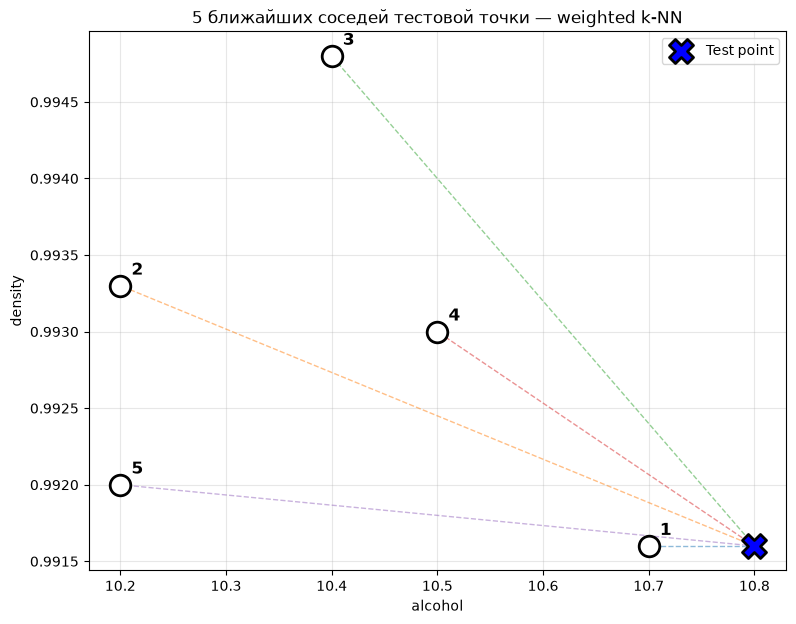

In [168]:
feature_x = 'alcohol'
feature_y = 'density'

x_idx = feature_names.index(feature_x)
y_idx = feature_names.index(feature_y)

k = 5

# Выбранная тестовая точка
test_point_idx = test_idx

# 5 ближайших соседей
neighbor_indices_5 = nearest_indices[test_point_idx, :k]
neighbor_distances_5 = nearest_distances[test_point_idx, :k]
neighbor_labels_5 = nearest_labels[test_point_idx, :k]

# Создаём график
plt.figure(figsize=(9, 7))

# Тестовая точка
test_x = X_test[test_point_idx, x_idx]
test_y = X_test[test_point_idx, y_idx]

plt.scatter(
    test_x,
    test_y,
    s=300,
    marker='X',
    c='blue',
    edgecolors='black',
    linewidths=2,
    label='Test point',
    zorder=10
)

# Рисуем только 5 ближайших соседей
for i in range(k):
    
    train_idx = neighbor_indices_5[i]
    
    neighbor_x = X_train[train_idx, x_idx]
    neighbor_y = X_train[train_idx, y_idx]
    
    label = neighbor_labels_5[i]
    point_color = 'red' if label == 0 else 'white'
    
    # Линия от тестовой точки до соседа
    plt.plot(
        [test_x, neighbor_x],
        [test_y, neighbor_y],
        linestyle='--',
        linewidth=1,
        alpha=0.5
    )
    
    # Сам сосед
    plt.scatter(
        neighbor_x,
        neighbor_y,
        s=220,
        c=point_color,
        edgecolors='black',
        linewidths=2,
        zorder=5
    )
    
    # Номер соседа
    plt.annotate(
        str(i + 1),
        (neighbor_x, neighbor_y),
        xytext=(8, 8),
        textcoords='offset points',
        fontsize=12,
        fontweight='bold'
    )

plt.xlabel(feature_x)
plt.ylabel(feature_y)

plt.title(
    f'5 ближайших соседей тестовой точки — weighted k-NN'
)

plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

In [169]:
red_weight = 0
white_weight = 0

for distance, label in zip(neighbor_distances, neighbor_labels):
    
    weight = 1 / (distance + 1e-10)
    
    if label == 0:
        red_weight += weight
    else:
        white_weight += weight

prediction = 1 if white_weight > red_weight else 0

print(f"Red weight:   {red_weight:.4f}")
print(f"White weight: {white_weight:.4f}")
print()
print("Предсказание:", 'white' if prediction == 1 else 'red')
print("Истинный класс:", 'white' if true_label == 1 else 'red')

Red weight:   0.0000
White weight: 3.3384

Предсказание: white
Истинный класс: white


## Перебор гиперпараметра

In [170]:
k_values = range(1, 31)

accuracies = []

for k in k_values:
    
    y_pred = weighted_knn_predict(
        nearest_distances,
        nearest_labels,
        k
    )
    
    accuracy = accuracy_score_manual(
        y_test,
        y_pred
    )
    
    accuracies.append(accuracy)
    
    print(f"k = {k:2d} | Accuracy = {accuracy:.4f}")

k =  1 | Accuracy = 0.9938
k =  2 | Accuracy = 0.9938
k =  3 | Accuracy = 0.9962
k =  4 | Accuracy = 0.9954
k =  5 | Accuracy = 0.9938
k =  6 | Accuracy = 0.9938
k =  7 | Accuracy = 0.9938
k =  8 | Accuracy = 0.9938
k =  9 | Accuracy = 0.9938
k = 10 | Accuracy = 0.9946
k = 11 | Accuracy = 0.9938
k = 12 | Accuracy = 0.9923
k = 13 | Accuracy = 0.9923
k = 14 | Accuracy = 0.9923
k = 15 | Accuracy = 0.9923
k = 16 | Accuracy = 0.9915
k = 17 | Accuracy = 0.9923
k = 18 | Accuracy = 0.9923
k = 19 | Accuracy = 0.9923
k = 20 | Accuracy = 0.9908
k = 21 | Accuracy = 0.9908
k = 22 | Accuracy = 0.9915
k = 23 | Accuracy = 0.9915
k = 24 | Accuracy = 0.9915
k = 25 | Accuracy = 0.9923
k = 26 | Accuracy = 0.9915
k = 27 | Accuracy = 0.9915
k = 28 | Accuracy = 0.9915
k = 29 | Accuracy = 0.9915
k = 30 | Accuracy = 0.9915


In [171]:
best_index = np.argmax(accuracies)

best_k = list(k_values)[best_index]
best_accuracy = accuracies[best_index]

print()
print(f"Лучший k: {best_k}")
print(f"Лучшая Accuracy: {best_accuracy:.4f}")
print(f"Лучшая Accuracy: {best_accuracy * 100:.2f}%")


Лучший k: 3
Лучшая Accuracy: 0.9962
Лучшая Accuracy: 99.62%


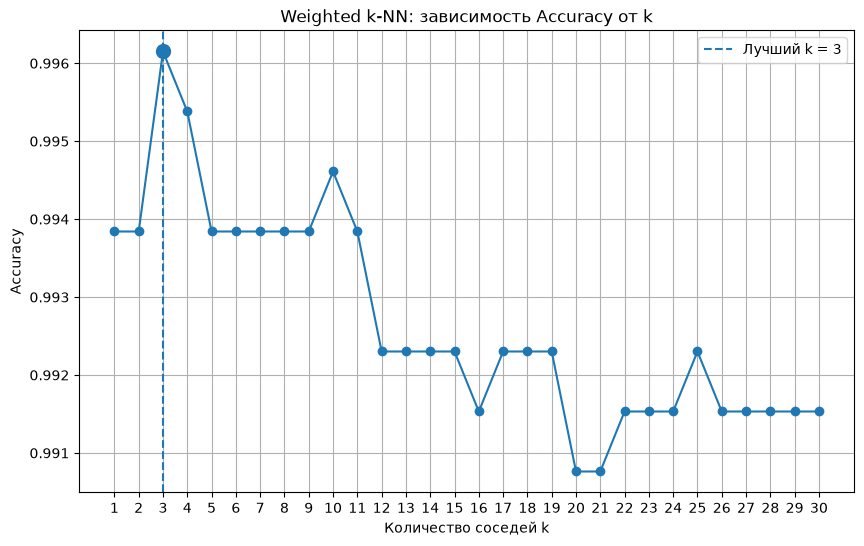

In [172]:
plt.figure(figsize=(10, 6))

plt.plot(
    list(k_values),
    accuracies,
    marker='o'
)

plt.axvline(
    best_k,
    linestyle='--',
    label=f'Лучший k = {best_k}'
)

plt.scatter(
    [best_k],
    [best_accuracy],
    s=100,
    zorder=5
)

plt.xlabel('Количество соседей k')
plt.ylabel('Accuracy')
plt.title('Weighted k-NN: зависимость Accuracy от k')
plt.xticks(list(k_values))
plt.grid(True)
plt.legend()

plt.show()